# TSP com TSPLIB95 e NetworkX

**Bases:** https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/

**Objetivo:** carregar uma instância do TSP simétrico, gerar rotas aleatórias válidas (sem repetição de cidades), calcular o custo automaticamente e desenhar as rotas.

**Instância:** `berlin52` (52 cidades, distância `EUC_2D`). Uma rota é uma **permutação** de todas as cidades; o percurso é um ciclo, portanto retorna à primeira cidade. O ótimo conhecido da instância é **7.542**.

## 1. Instalar as bibliotecas

## 2. Importar bibliotecas e obter o arquivo `berlin52.tsp`

In [29]:
import random

import matplotlib.pyplot as plt
import networkx as nx
import tsplib95

arquivo = 'berlin52.tsp'

## 3. Carregar a instância e examinar as cidades

`get_nodes()` fornece os identificadores das cidades. `node_coords` fornece as coordenadas usadas no desenho.

In [30]:
problema = tsplib95.load(arquivo)
cidades = list(problema.get_nodes())

print('Instância:', problema.name)
print('Tipo:', problema.type)
print('Distância:', problema.edge_weight_type)
print('Quantidade de cidades:', len(cidades))
print('Coordenadas da cidade 1:', problema.node_coords[cidades[0]])

Instância: berlin52
Tipo: TSP
Distância: EUC_2D
Quantidade de cidades: 52
Coordenadas da cidade 1: [565.0, 575.0]


## 4. Gerar uma rota aleatória válida com um comando

`random.sample(cidades, k=len(cidades))` devolve todas as cidades em ordem aleatória **sem repetição**. Uma rota é armazenada sem repetir a primeira cidade no final: o fechamento é feito durante a avaliação e a visualização.

In [31]:
rota = random.sample(cidades, k=len(cidades))
print('Rota aleatória:', rota)
print('Número de cidades:', len(rota))
print('Cidades distintas:', len(set(rota)))

Rota aleatória: [6, 31, 29, 8, 28, 51, 40, 4, 27, 23, 38, 18, 13, 30, 33, 1, 50, 22, 39, 26, 24, 9, 37, 15, 21, 52, 5, 46, 11, 12, 48, 3, 10, 45, 20, 14, 7, 44, 2, 43, 25, 47, 35, 17, 36, 42, 49, 41, 34, 32, 19, 16]
Número de cidades: 52
Cidades distintas: 52


## 5. Validar a rota

Uma rota válida deve conter **todas** as cidades exatamente uma vez.

In [24]:
def rota_valida(rota, cidades):
    return len(rota) == len(cidades) and set(rota) == set(cidades)

print('Rota válida?', rota_valida(rota, cidades))

Rota válida? True


## 6. Calcular o custo da rota usando a própria TSPLIB95

`problema.get_weight(origem, destino)` calcula a distância segundo a regra da instância. O operador `%` conecta a última cidade à primeira.

In [32]:
def custo_rota(rota, problema):
    custo = 0
    for i in range(len(rota)):
        origem = rota[i]
        destino = rota[(i + 1) % len(rota)]
        custo += problema.get_weight(origem, destino)
    return custo

print('Custo total da rota:', custo_rota(rota, problema))
print('Primeiro trecho:', rota[0], '-', rota[1], '=', problema.get_weight(rota[0], rota[1]))

Custo total da rota: 31028
Primeiro trecho: 6 - 31 = 472


## 7. Desenhar a rota usando NetworkX

O grafo contém as 52 cidades e apenas as **arestas da rota escolhida**. As posições vêm das coordenadas originais da TSPLIB. A aresta de retorno fecha o ciclo.

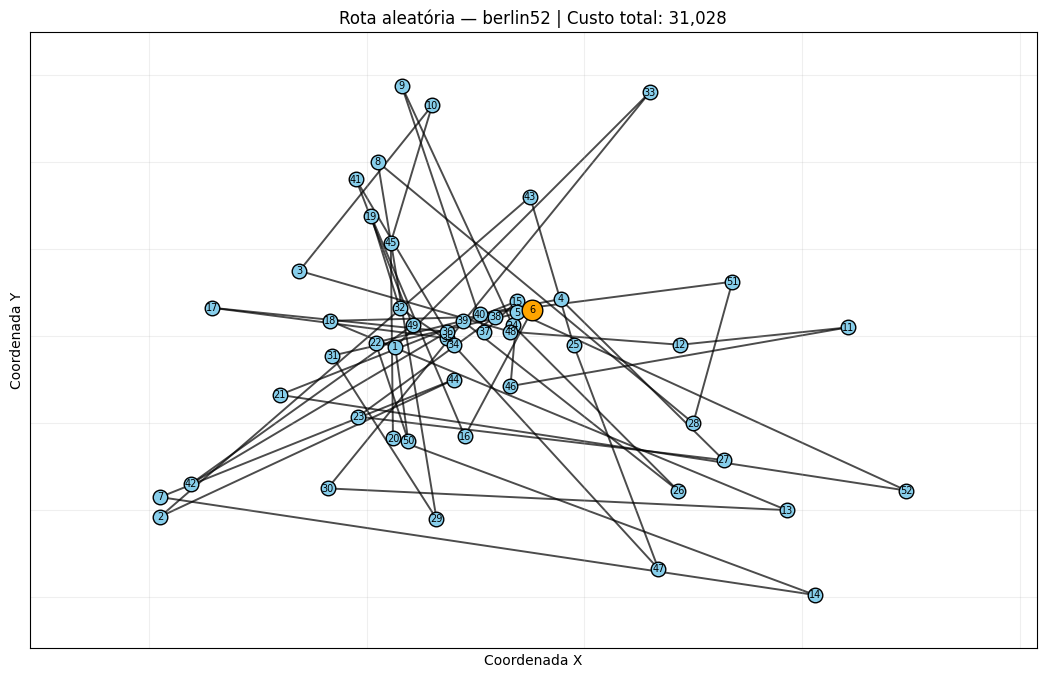

In [33]:
def desenhar_rota(rota, problema, titulo='Rota TSP'):
    grafo = nx.Graph()
    grafo.add_nodes_from(rota)
    arestas = [
        (rota[i], rota[(i + 1) % len(rota)])
        for i in range(len(rota))
    ]
    grafo.add_edges_from(arestas)

    pos = {cidade: tuple(problema.node_coords[cidade]) for cidade in rota}
    plt.figure(figsize=(13, 8))
    nx.draw_networkx_edges(grafo, pos, width=1.4, alpha=0.7)
    nx.draw_networkx_nodes(grafo, pos, node_size=110, node_color='skyblue', edgecolors='black')
    nx.draw_networkx_labels(grafo, pos, font_size=7)
    nx.draw_networkx_nodes(grafo, pos, nodelist=[rota[0]], node_size=220,
                           node_color='orange', edgecolors='black')
    plt.title(f'{titulo} | Custo total: {custo_rota(rota, problema):,.0f}')
    plt.xlabel('Coordenada X')
    plt.ylabel('Coordenada Y')
    plt.axis('equal')
    plt.grid(alpha=0.2)
    plt.show()
    return grafo

grafo_rota = desenhar_rota(rota, problema, 'Rota aleatória — berlin52')

## 8. Gerar várias rotas aleatórias e escolher a de menor custo



In [27]:
quantidade_rotas = 100
resultados = []

for _ in range(quantidade_rotas):
    candidata = random.sample(cidades, k=len(cidades))
    resultados.append((custo_rota(candidata, problema), candidata))

melhor_custo, melhor_rota = min(resultados, key=lambda resultado: resultado[0])
print('Rotas avaliadas:', quantidade_rotas)
print('Melhor custo encontrado:', melhor_custo)
print('Melhor rota:', melhor_rota)

Rotas avaliadas: 100
Melhor custo encontrado: 24233
Melhor rota: [36, 21, 20, 40, 38, 28, 35, 26, 52, 51, 11, 16, 10, 4, 32, 22, 27, 50, 34, 43, 47, 14, 12, 13, 45, 24, 15, 44, 18, 23, 5, 39, 8, 25, 49, 1, 46, 33, 17, 37, 31, 3, 9, 6, 42, 7, 41, 19, 2, 30, 29, 48]


## 9. Visualizar a melhor rota aleatória

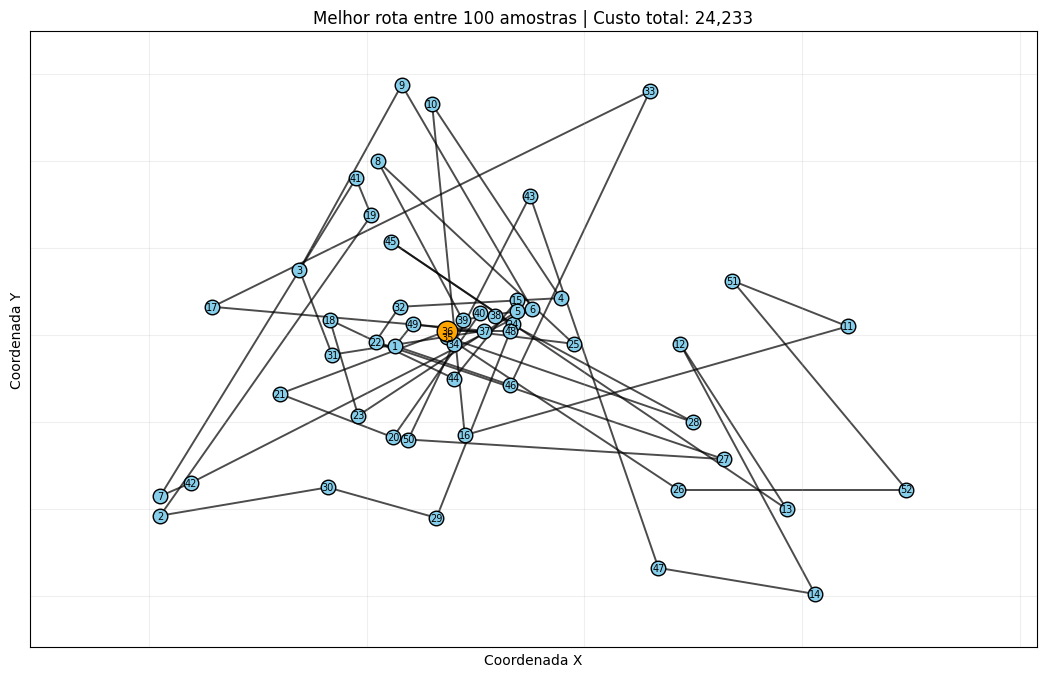

In [28]:
grafo_melhor = desenhar_rota(melhor_rota, problema, 'Melhor rota entre 100 amostras')